# SkinWise AI — Analyse exploratoire des données (EDA)

**Dataset :** ACNE04 — 4 grades de sévérité de l'acné (échelle de Hayashi)

Ce notebook explore le dataset **avant** la modélisation, pour justifier les choix du pipeline :

1. Inventaire des fichiers et distribution des classes
2. Propriétés des images (taille, format, poids)
3. Exemples visuels par grade
4. Statistiques de couleur et de luminosité par classe
5. **Recherche de doublons** et vérification de la division train / val / test (fuite de données)
6. Effet du redimensionnement 1024 → 224 px
7. Conclusions pour la modélisation

> Le pipeline réel (division, entraînement, évaluation) est dans `src/`. Ce notebook ne fait que **lire** les données, il ne modifie rien.

In [ ]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# The notebook can be launched from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw" / "acne_1024"
SPLIT_DIR = ROOT / "data" / "processed"

CLASS_NAMES = {0: "Mild (N0)", 1: "Moderate (N1)", 2: "Severe (N2)", 3: "Very Severe (N3)"}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ebeae6", "axes.axisbelow": True})
print("Dataset :", DATA_DIR, "| trouvé :", DATA_DIR.exists())

Dataset : /home/claude/sw/data/raw/acne_1024 | trouvé : True


## 1. Inventaire des fichiers et distribution des classes

Chaque sous-dossier `acneX_1024` correspond à un grade de sévérité.

In [2]:
all_files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())
images = [p for p in all_files if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
others = [p for p in all_files if p not in images]

df = pd.DataFrame({
    "path": [p.relative_to(DATA_DIR).as_posix() for p in images],
    "label": [int(p.parent.name[4]) for p in images],          # acne0_1024 -> 0
})
df["class_name"] = df["label"].map(CLASS_NAMES)

print(f"Fichiers totaux : {len(all_files)} | images : {len(images)} | autres fichiers : {len(others)}")
for p in others:
    print("  -", p.relative_to(DATA_DIR))

counts = df["class_name"].value_counts().reindex(CLASS_NAMES.values())
summary = pd.DataFrame({"images": counts, "part (%)": (counts / counts.sum() * 100).round(1)})
summary

Fichiers totaux : 1378 | images : 1377 | autres fichiers : 1
  - acne3_1024/metadata_acne3.jsonl


,images,part (%)
class_name,,
Mild (N0),483,35.1
Moderate (N1),623,45.2
Severe (N2),175,12.7
Very Severe (N3),96,7.0


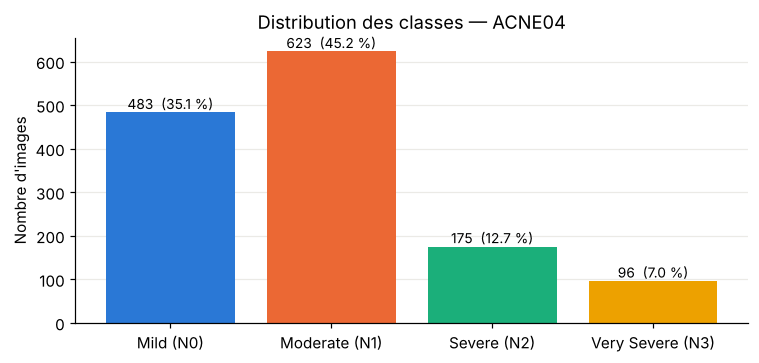

Rapport de déséquilibre (classe majoritaire / minoritaire) : 6.5 : 1


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(summary.index, summary["images"], color=COLORS)
for b, n, pct in zip(bars, summary["images"], summary["part (%)"]):
    ax.text(b.get_x() + b.get_width() / 2, n + 8, f"{n}  ({pct} %)", ha="center", fontsize=9)
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des classes — ACNE04")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

ratio = counts.max() / counts.min()
print(f"Rapport de déséquilibre (classe majoritaire / minoritaire) : {ratio:.1f} : 1")

**Observation :** le dataset est fortement déséquilibré : *Moderate* représente 45 % des images
et *Very Severe* seulement 7 % (rapport ≈ 6,5 : 1). Un modèle qui prédirait toujours « Moderate »
aurait déjà 45 % d'accuracy.

➡️ **Conséquences :** division **stratifiée**, sélection du modèle sur le **Macro-F1** (et pas l'accuracy),
et pistes de rééquilibrage (poids de classe, Focal Loss).

### Le fichier `metadata_acne3.jsonl`

Le dossier `acne3_1024` contient un fichier texte en plus des images.

In [4]:
meta_path = DATA_DIR / "acne3_1024" / "metadata_acne3.jsonl"
meta = [json.loads(line) for line in meta_path.read_text(encoding="utf-8").splitlines() if line.strip()]
meta_names = {m["file_name"] for m in meta}
on_disk = {Path(p).name for p in df.loc[df["label"] == 3, "path"]}

print(f"Entrées dans le fichier : {len(meta)}")
print(f"Images N3 présentes sur le disque : {len(on_disk)}")
print(f"Entrées sans image correspondante : {len(meta_names - on_disk)}")
print("\nExemples :")
for m in meta[:3]:
    print(" ", m)

Entrées dans le fichier : 115
Images N3 présentes sur le disque : 96
Entrées sans image correspondante : 19

Exemples :
  {'file_name': 'levle3_87.jpg', 'prompt': 'photo of a person with acne3, a woman with ac ac ac ac ac ac ac ac ac ac ac ac ac ac ac ac ac ac'}
  {'file_name': 'levle3_85.jpg', 'prompt': 'photo of a person with acne3, a woman with acne on her face'}
  {'file_name': 'levle3_142.jpg', 'prompt': 'photo of a person with acne3, a man with a lot of bruises on his face'}


**Observation :** ce fichier contient des légendes textuelles (*prompts*) destinées à des modèles
génératifs, dont 19 renvoient à des images absentes. Il n'est **pas utilisé** pour la classification :
`src/data/dataset.py` ne charge que les fichiers image.

## 2. Propriétés des images

In [5]:
records = []
for p in images:
    raw = p.read_bytes()
    with Image.open(p) as im:
        records.append({"width": im.width, "height": im.height, "mode": im.mode,
                        "format": im.format, "size_kb": len(raw) / 1024,
                        "md5": hashlib.md5(raw).hexdigest()})
props = pd.DataFrame(records)
df = pd.concat([df, props], axis=1)

print("Dimensions :", df.groupby(["width", "height"]).size().to_dict())
print("Mode couleur :", df["mode"].value_counts().to_dict())
print("Format :", df["format"].value_counts().to_dict())
df.groupby("class_name")["size_kb"].describe()[["mean", "min", "max"]].round(1).reindex(CLASS_NAMES.values())

Dimensions : {(1024, 1024): 1377}
Mode couleur : {'RGB': 1377}
Format : {'JPEG': 1377}


,mean,min,max
class_name,,,
Mild (N0),115.2,42.4,167.2
Moderate (N1),115.4,28.7,182.3
Severe (N2),107.5,38.3,168.6
Very Severe (N3),84.0,36.3,156.7


**Observation :** les 1 377 images sont **toutes** en 1024×1024, RGB, JPEG. Aucun prétraitement
de format n'est nécessaire, et un simple redimensionnement suffit pour le modèle.
Les images *Very Severe* sont nettement plus légères (≈ 84 Ko contre ≈ 115 Ko) : elles proviennent
probablement de conditions de prise de vue différentes (voir section 4).

## 3. Exemples visuels par grade

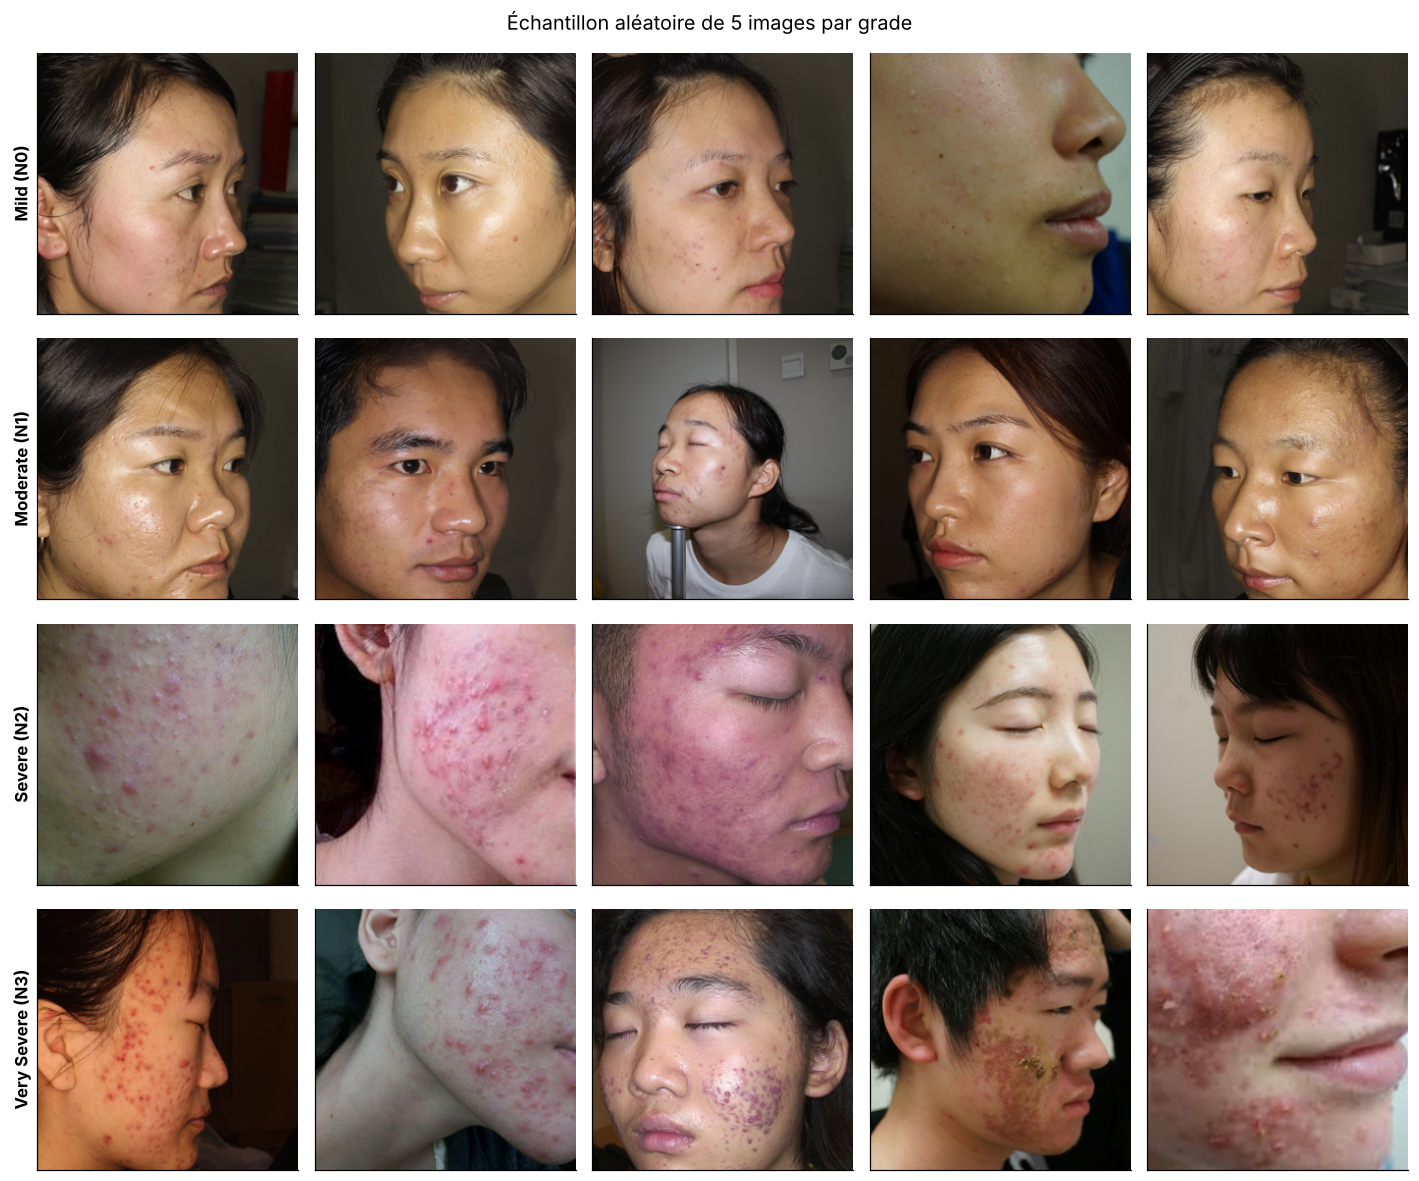

In [6]:
rng = np.random.default_rng(42)
n_per_class = 5
fig, axes = plt.subplots(4, n_per_class, figsize=(13, 11))
for c in range(4):
    sample = df[df["label"] == c].sample(n_per_class, random_state=42)
    for k, rel in enumerate(sample["path"]):
        ax = axes[c, k]
        ax.imshow(Image.open(DATA_DIR / rel).resize((256, 256)))
        ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(CLASS_NAMES[c], fontsize=11, fontweight="bold")
plt.suptitle("Échantillon aléatoire de 5 images par grade", fontsize=13)
plt.tight_layout(); plt.show()

**Observation :** les images sont des photos de visage de profil ou de trois-quarts. Les lésions
occupent une petite partie de l'image, surtout pour les grades faibles. La différence entre deux grades
voisins (ex. *Moderate* / *Severe*) tient au **nombre** de lésions, ce qui est difficile à voir
à basse résolution.

## 4. Couleur et luminosité par classe

In [7]:
def color_stats(rel):
    a = np.asarray(Image.open(DATA_DIR / rel).convert("RGB").resize((64, 64)), dtype=np.float32)
    r, g, b = a[..., 0].mean(), a[..., 1].mean(), a[..., 2].mean()
    return pd.Series({"R": float(r), "G": float(g), "B": float(b), "luminosite": float((r + g + b) / 3),
                      "rougeur": float(r - (g + b) / 2)})

stats = df["path"].apply(color_stats)
df = pd.concat([df, stats], axis=1)
df.groupby("class_name")[["R", "G", "B", "luminosite", "rougeur"]].mean().round(1).reindex(CLASS_NAMES.values())

,R,G,B,luminosite,rougeur
class_name,,,,,
Mild (N0),116.6,90.5,70.9,92.6,35.9
Moderate (N1),116.4,90.1,71.1,92.5,35.8
Severe (N2),119.7,93.3,76.8,96.6,34.6
Very Severe (N3),134.8,105.1,95.8,111.9,34.4


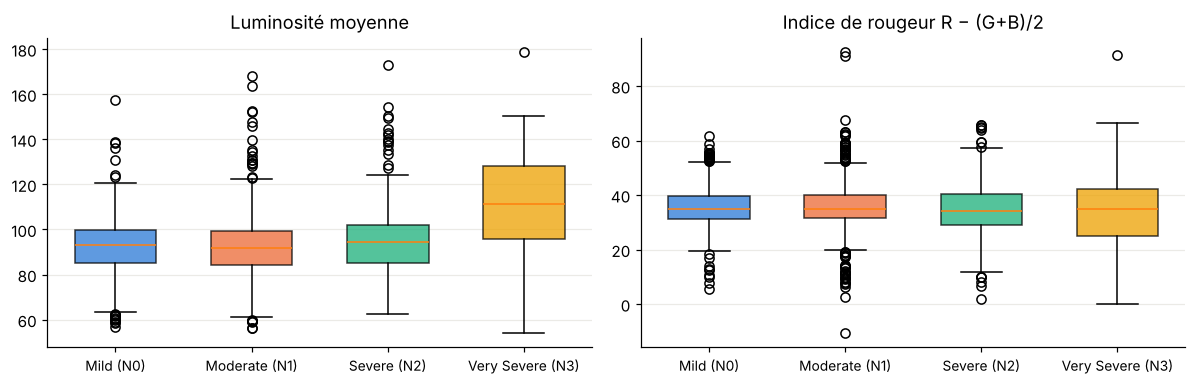

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "luminosite", "Luminosité moyenne"), (axes[1], "rougeur", "Indice de rougeur R − (G+B)/2")]:
    data = [df.loc[df["label"] == c, col] for c in range(4)]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    for patch, color in zip(bp["boxes"], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.75)
    ax.set_xticks(range(1, 5), list(CLASS_NAMES.values()), fontsize=9)
    ax.set_title(title); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Observation :** la « rougeur » moyenne de l'image entière **ne distingue pas** les grades : les lésions
sont trop petites pour peser sur la moyenne. En revanche, les images *Very Severe* sont nettement
plus **claires**. C'est un biais d'acquisition, pas un signe médical : le modèle pourrait l'apprendre
comme raccourci.

➡️ **Conséquences :** la classification ne peut pas reposer sur des statistiques globales simples, ce qui
justifie un CNN. L'augmentation de luminosité/contraste (`ColorJitter`) aide à empêcher le modèle
d'utiliser l'éclairage comme indice.

## 5. Recherche de doublons et vérification de la division

Une même photo présente deux fois dans le dataset peut se retrouver à la fois dans le train et dans le test
(**fuite de données**). On compare donc l'empreinte MD5 de chaque fichier : deux fichiers avec la
même empreinte sont **identiques octet par octet**.

In [9]:
dup_groups = [g for _, g in df.groupby("md5") if len(g) > 1]
print(f"Groupes de fichiers identiques : {len(dup_groups)}")
print(f"Images concernées : {sum(len(g) for g in dup_groups)} sur {len(df)}")

conflicts = [g for g in dup_groups if g["label"].nunique() > 1]
print(f"\nDoublons avec des étiquettes DIFFÉRENTES : {len(conflicts)}")
pd.DataFrame([{"image A": g.iloc[0]["path"], "image B": g.iloc[1]["path"],
               "grade A": g.iloc[0]["label"], "grade B": g.iloc[1]["label"]} for g in conflicts])

Groupes de fichiers identiques : 36
Images concernées : 72 sur 1377

Doublons avec des étiquettes DIFFÉRENTES : 8


,image A,image B,grade A,grade B
0,acne1_1024/levle1_23.jpg,acne2_1024/levle2_153.jpg,1,2
1,acne0_1024/levle0_121.jpg,acne1_1024/levle1_504.jpg,0,1
2,acne1_1024/levle1_131.jpg,acne2_1024/levle2_128.jpg,1,2
3,acne1_1024/levle1_20.jpg,acne2_1024/levle2_151.jpg,1,2
4,acne1_1024/levle1_22.jpg,acne2_1024/levle2_152.jpg,1,2
5,acne0_1024/levle0_185.jpg,acne1_1024/levle1_286.jpg,0,1
6,acne0_1024/levle0_120.jpg,acne1_1024/levle1_486.jpg,0,1
7,acne1_1024/levle1_16.jpg,acne2_1024/levle2_150.jpg,1,2


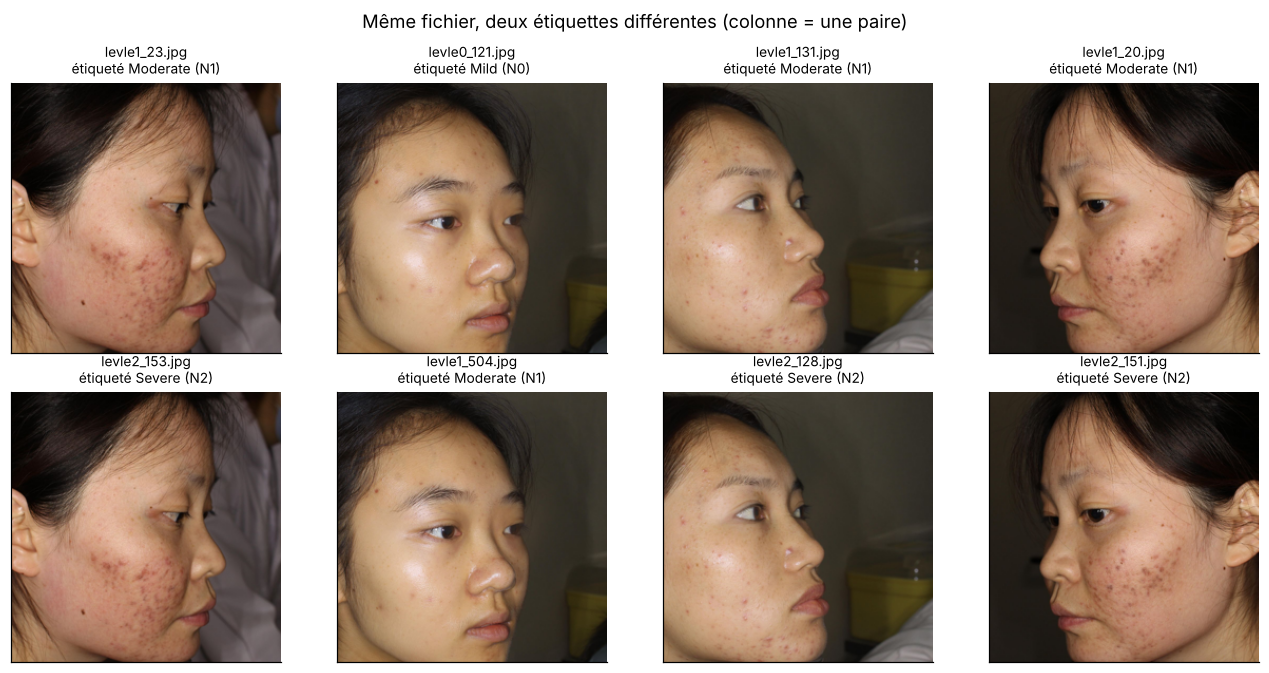

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for k, g in enumerate(conflicts[:4]):
    for row in range(2):
        r = g.iloc[row]
        ax = axes[row, k]
        ax.imshow(Image.open(DATA_DIR / r["path"]).resize((256, 256)))
        ax.set_title(f"{Path(r['path']).name}\nétiqueté {CLASS_NAMES[r['label']]}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Même fichier, deux étiquettes différentes (colonne = une paire)", fontsize=12)
plt.tight_layout(); plt.show()

**Observation :** ACNE04 contient **36 paires de fichiers identiques**, dont **8 portent deux étiquettes
différentes** (toujours des grades voisins : N0/N1 ou N1/N2). Cela montre que la frontière entre
grades voisins est ambiguë même pour les annotateurs : une partie des erreurs du modèle entre grades
adjacents est donc inévitable.

### Ces doublons faussent-ils le score de test ?

On charge la division réellement utilisée pour l'entraînement (`data/processed/*.csv`, seed = 42).

In [11]:
split = pd.concat([pd.read_csv(SPLIT_DIR / f"{s}.csv").assign(split=s) for s in ["train", "val", "test"]])
df = df.merge(split[["image_path", "split"]], left_on="path", right_on="image_path", how="left").drop(columns="image_path")

# 1) Each image belongs to exactly one partition
print("Images sans partition :", df["split"].isna().sum())
print("Chemins présents dans plusieurs partitions :", split["image_path"].duplicated().sum())

# 2) Class proportions per partition (stratification check)
prop = pd.crosstab(df["class_name"], df["split"], normalize="columns").mul(100).round(1)
prop = prop.reindex(CLASS_NAMES.values())[["train", "val", "test"]]
print("\nProportion de chaque classe par partition (%) :")
prop

Images sans partition : 0
Chemins présents dans plusieurs partitions : 0

Proportion de chaque classe par partition (%) :


split,train,val,test
class_name,,,
Mild (N0),35.1,35.1,34.9
Moderate (N1),45.3,45.4,45.0
Severe (N2),12.7,12.7,12.9
Very Severe (N3),7.0,6.8,7.2


In [12]:
# 3) Test images that have an identical copy in the TRAINING set
dup_groups = [g for _, g in df.groupby("md5") if len(g) > 1]   # recompute with the split column
leaked = []
for g in dup_groups:
    if "test" in set(g["split"]) and "train" in set(g["split"]):
        leaked += g.loc[g["split"] == "test", "path"].tolist()

cross = sum(g["split"].nunique() > 1 for g in dup_groups)
print(f"Paires de doublons réparties sur deux partitions : {cross}")
print(f"Images de test ayant une copie identique dans le train : {len(leaked)} sur {(df['split'] == 'test').sum()}")
for p in leaked:
    print("  -", p)

Paires de doublons réparties sur deux partitions : 16
Images de test ayant une copie identique dans le train : 4 sur 209
  - acne1_1024/levle1_503.jpg
  - acne1_1024/levle1_485.jpg
  - acne1_1024/levle1_289.jpg
  - acne0_1024/levle0_120.jpg


In [13]:
# 4) Re-evaluate the trained ONNX model with and without these images (optional: needs onnxruntime)
try:
    import onnxruntime as ort
    sess = ort.InferenceSession(str(ROOT / "models" / "best_model.onnx"), providers=["CPUExecutionProvider"])
    inp = sess.get_inputs()[0].name
    mean = np.array([0.485, 0.456, 0.406], np.float32); std = np.array([0.229, 0.224, 0.225], np.float32)

    def predict(rel):
        a = np.asarray(Image.open(DATA_DIR / rel).convert("RGB").resize((224, 224), Image.BILINEAR), np.float32) / 255
        x = ((a - mean) / std).transpose(2, 0, 1)[None].astype(np.float32)
        return int(np.argmax(sess.run(None, {inp: x})[0]))

    def macro_f1(y, p):
        f1 = []
        for c in range(4):
            tp = ((p == c) & (y == c)).sum()
            prec, rec = tp / max((p == c).sum(), 1), tp / max((y == c).sum(), 1)
            f1.append(0.0 if tp == 0 else 2 * prec * rec / (prec + rec))
        return float(np.mean(f1))

    test = df[df["split"] == "test"].copy()
    test["pred"] = test["path"].apply(predict)
    clean = test[~test["path"].isin(leaked)]
    rows = []
    for name, t in [("Test complet", test), ("Test sans doublons du train", clean)]:
        y, p = t["label"].to_numpy(), t["pred"].to_numpy()
        rows.append({"jeu": name, "images": len(t), "accuracy": round((y == p).mean(), 4), "macro_f1": round(macro_f1(y, p), 4)})
    display(pd.DataFrame(rows))
except (ImportError, FileNotFoundError) as exc:
    print("Section ignorée (onnxruntime ou models/best_model.onnx manquant) :", exc)

,jeu,images,accuracy,macro_f1
0,Test complet,209,0.7703,0.7292
1,Test sans doublons du train,205,0.7707,0.7299


**Observation :**
- La division est correcte : chaque image appartient à une seule partition et les proportions de classes
  sont identiques dans train, val et test (stratification).
- Les doublons propres au dataset font que **4 images de test sur 209** existent aussi dans le train.
- En les retirant, le score est **pratiquement inchangé** (≈ 77,1 % d'accuracy, Macro-F1 ≈ 0,73) :
  le résultat du modèle **n'est pas gonflé** par ces doublons.

➡️ **Amélioration prévue :** dédoublonner par empreinte MD5 *avant* la division dans `src/data/dataset.py`
(et retirer les 8 paires contradictoires) lors du prochain entraînement.

## 6. Effet du redimensionnement 1024 → 224 px

Le modèle reçoit des images de 224×224, soit **≈ 21 fois moins de pixels** que l'original.
On compare une même zone de joue avant et après réduction.

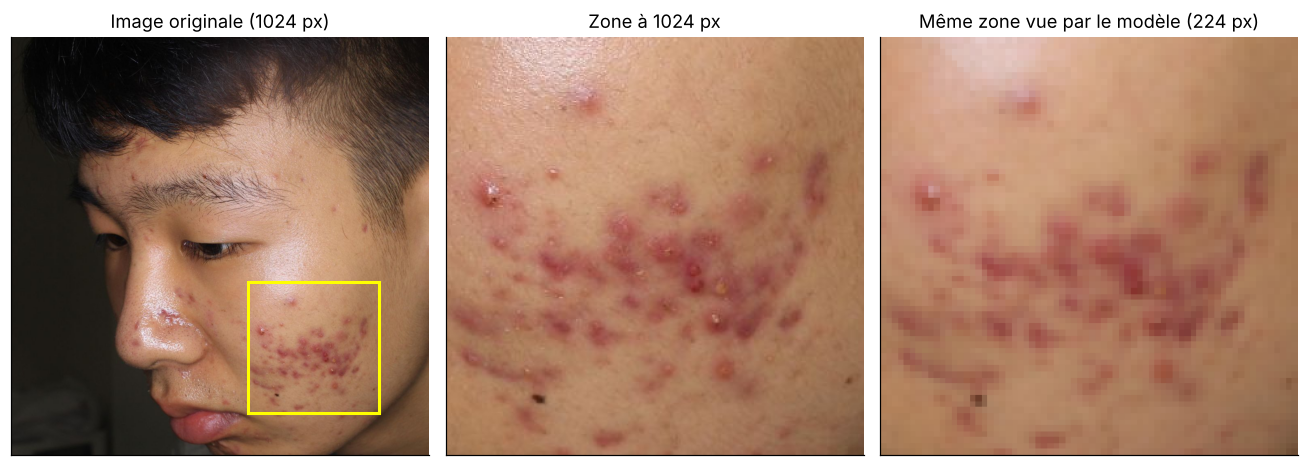

In [14]:
example = df[df["label"] == 2].iloc[5]["path"]
full = Image.open(DATA_DIR / example).convert("RGB")
small = full.resize((224, 224), Image.BILINEAR)

box = (580, 600, 900, 920)                       # cheek region with lesions (1024 px image)
crop_full = full.crop(box)
s = 224 / 1024
crop_small = small.crop(tuple(int(v * s) for v in box)).resize(crop_full.size, Image.NEAREST)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
axes[0].imshow(full); axes[0].add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, ec="yellow", lw=2))
axes[0].set_title("Image originale (1024 px)")
axes[1].imshow(crop_full); axes[1].set_title("Zone à 1024 px")
axes[2].imshow(crop_small); axes[2].set_title("Même zone vue par le modèle (224 px)")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Observation :** à 224 px, les petites papules deviennent quelques pixels flous : compter les lésions,
qui est le critère qui sépare les grades, devient très difficile.

➡️ **Conséquence :** augmenter la résolution d'entrée (384 px, ou EfficientNet-B2/B3) est la piste
d'amélioration la plus prometteuse, en particulier pour la classe *Severe*.

## 7. Conclusions pour la modélisation

| Constat de l'EDA | Décision dans le projet |
|---|---|
| Classes déséquilibrées (45 % vs 7 %) | Division stratifiée, sélection du modèle sur le **Macro-F1**, poids de classe ajoutés au code |
| Toutes les images en 1024×1024 RGB JPEG | Pas de nettoyage de format ; simple redimensionnement + normalisation ImageNet |
| Peu d'images (1 377) | **Transfer learning** (EfficientNet-B0 pré-entraîné) + augmentation de données |
| Lésions petites, perdues à 224 px | Piste d'amélioration : résolution plus élevée |
| Les *Very Severe* sont plus claires (biais d'acquisition) | Augmentation de luminosité/contraste (`ColorJitter`) |
| 36 doublons, dont 8 avec des étiquettes contradictoires | Frontière ambiguë entre grades voisins ; dédoublonnage prévu avant la division |
| 4 images de test ont une copie dans le train | Impact mesuré : négligeable (score inchangé sans elles) |
| Fichier `metadata_acne3.jsonl` (légendes pour IA générative) | Ignoré par le pipeline |